# 24. How a splat keeps track of its neighbour

[Course plan](../../README.md)

Two identical splats sit on a rotating part. Fitting two fresh centers in the next frame can make a convincing image. Which new center belongs to which old splat? The image alone may have no opinion.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "dynamic_motion.py").is_file())
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
import dynamic_motion as motion
from dynamic_motion_demos import motion_figure, motion_lab
lang = 'en'

## One image, two histories

Both splats have the same color, shape and opacity. At first their centers sit 0.4 m left and right of the midpoint. In the next frame there are splats in exactly the same places. Perhaps they both stayed still. Perhaps they traded places between exposures. The splat that starts on the left carries the label A, the one on the right B. The letters stand for persistent array indices. They do not appear in the image.

The code renders both final frames with the same compositor used for the static scene. In one history A has travelled 0 m, in the other $0.4-(-0.4)=0.8$ m. Swapping two contributions with identical colors leaves the pixel difference at zero to numerical precision.

In [2]:
from splat_render import make_scene, splat, render_scene, translated_camera
def dot(x):
    return splat([x, 0, 4], [.16, .12, .1], [.9, .3, .1], .9)
stationary, exchanged = make_scene(dot(-.4), dot(.4)), make_scene(dot(.4), dot(-.4))
frames = [render_scene(s, translated_camera(0, 80), 97, 61) for s in [stationary, exchanged]]
print('A: 0 or 0.8 m   max |ΔRGB| =', np.max(np.abs(frames[0] - frames[1])))

A: 0 or 0.8 m   max |ΔRGB| = 1.1102230246251565e-16


## What a neighbour can tell us

An elongated shape makes A's orientation visible. Between exposures its long axis makes a quarter turn. If B sits on the same rigid part, the edge between their centers turns with A. In this experiment A sits at the origin of the current frame. Blue marks the tip of the rigidly rotated edge, green the true B and orange our estimate from measurements. The bend control lets the neighbour move relative to the part.

In [3]:
display(motion_lab(24, lang))

## Rotating an edge, in numbers

In the previous frame A was at $(-0.4,-0.2)$ m and B at $(0.4,-0.2)$ m. The edge from A to B comes from subtracting their coordinates component by component. Horizontally, $0.4-(-0.4)=0.8$ m. Vertically, $-0.2-(-0.2)=0$. The edge is $(0.8,0)$. When A moves to $(0,0)$, translating the part leaves the edge length alone.

The angle of the turn is $\theta$. Positive y points down, as in an image. A $90^\circ$ turn sends a rightward arrow downward. At an arbitrary angle the unit rightward arrow becomes $(\cos\theta,\sin\theta)$. Multiplying each component by the length of 0.8 m gives the expected tip $r$. With $\cos90^\circ=0$ and $\sin90^\circ=1$ it lands at $r=(0,0.8)$ m.

The orange measurement in the current frame put B at $q=(0.4,0.6)$ m. The difference is $q-r=(0.4,-0.2)$ m. Its Euclidean length is $\sqrt{0.4^2+(-0.2)^2}=\sqrt{0.20}\approx0.447$ m. Placing B right on the mark would leave that much tracking error for a truly rigid turn.

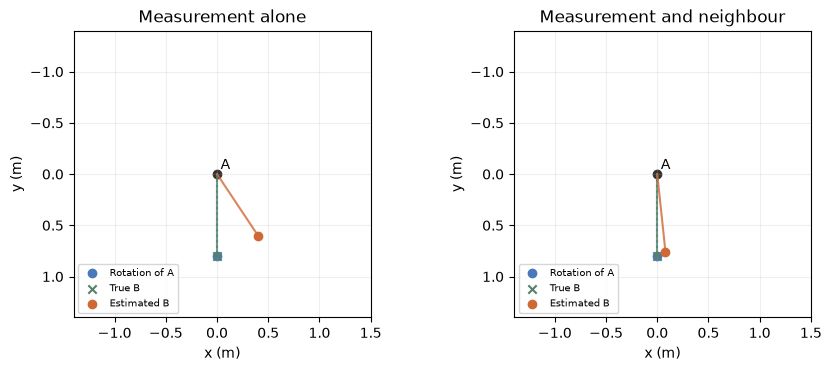

In [4]:
fig = motion_figure(24, lang, strength=4)
plt.show()

## Combining the mark and the rotation

One coordinate is enough to see how the fit works. The trial position $b$, the measurement $q$ and the rotation prediction $r$ are all in metres. The fit adds the squared distance to the mark and a weighted squared distance to the rigid prediction. The weight $\lambda$ is nonnegative and dimensionless. At $\lambda=4$ a displacement of a given size away from the rigid neighbour costs four times as much as the same displacement away from the mark. Both terms are in square metres.

$$
L(b)=(b-q)^2+\lambda(b-r)^2.
$$

The derivative of a square from lesson 7 is twice the residual. The derivatives add, and their sum vanishes at the bottom of the bowl. Dividing both sides by 2, collecting the terms in $b$ on the left and factoring gives

$$
\begin{aligned}
2(b-q)+2\lambda(b-r)&=0,\\
b+\lambda b&=q+\lambda r,\\
b&=\frac{q+\lambda r}{1+\lambda}.
\end{aligned}
$$

The denominator stays positive even at zero weight. Horizontally the fit gives $(0.4+4\cdot0)/5=0.08$ m. Vertically it gives $(0.6+4\cdot0.8)/5=0.76$ m. The displacement from the rigid prediction has fallen to $(0.08,-0.04)$ m, about 0.089 m in length. The formula is the exact minimizer for this small squared-error problem.

In [5]:
for weight in [0, 1, 4, 10]:
    result = motion.persistent_pair(strength=weight)
    print(f"λ={weight:2d}   B={np.round(result['fitted'],3)} m   |Δ|={result['tracking_error']:.4f} m")

λ= 0   B=[0.4 0.6] m   |Δ|=0.4472 m
λ= 1   B=[0.2 0.7] m   |Δ|=0.2236 m
λ= 4   B=[0.08 0.76] m   |Δ|=0.0894 m
λ=10   B=[0.036 0.782] m   |Δ|=0.0407 m


## From one pair to Dynamic 3D Gaussians

Luiten and colleagues reconstruct the first instant as a static scene from multiple cameras. At later instants the same Gaussians update their centers and rotations. In the paper's model their size, color and opacity persist. Rendered images are compared with camera images. This fitting process does not need supplied point tracks. [Project and results](https://dynamic3dgaussians.github.io/)

The authors select each Gaussian's 20 nearest neighbours using positions in the first frame. A pair that starts closer together gets more weight. Three penalties serve different purposes. One compares the edge between consecutive instants after accounting for A's rotation, much as our pair experiment does. Another compares the changes in the orientations of A and B **themselves** over one step. Two splats can keep their positions but turn their long axes by different amounts. The third compares the **length** of the current edge with its length in the first frame. Small increments of stretch are then detectable even as they accumulate over many frames. [Three neighbourhood constraints](https://arxiv.org/html/2308.09713v1)

Our experiment supplies A's rotation and a measured position for B. The original fits many centers and orientations together using the images and local constraints. Squaring a distance in our small example makes a solution by hand possible. The paper's local rigidity expression uses the length of a vector residual. The public training code also allows a small color change with a penalty. [Authors' implementation](https://github.com/JonathonLuiten/Dynamic3DGaussians/blob/main/train.py)

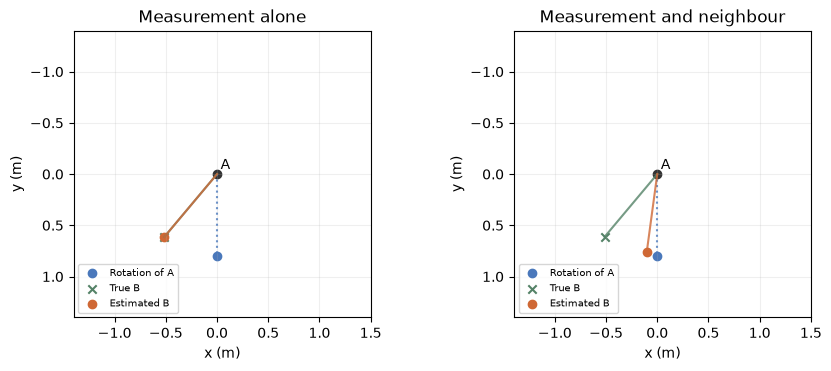

In [6]:
fig = motion_figure(24, lang, strength=4, noise=0, bend=40)
plt.show()

**At a hinge.** The measurement is exact but the part bends an extra $40^\circ$ relative to A's turn. What does a strong neighbour weight do?

<details><summary>Worked answer</summary>

With zero noise the measurement is the true B. At $\lambda=0$ orange coincides with green. Increasing the weight pulls it toward the blue endpoint, which assumes rigidity. At $\lambda=4$ the two predictions receive weights in the ratio four to one. The estimated point travels four fifths of the way from the correct mark toward the wrong rigid prediction. Even good first-frame neighbours may move differently on opposite sides of a hinge.

</details>